In [1]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
                    roc_auc_score,confusion_matrix,ConfusionMatrixDisplay,classification_report)



In [4]:
#load the dataset
data_df = pd.read_csv("train_set.csv")
display(data_df.head())
print("Shape of Dataset \n",data_df.shape)

,Applicant_ID,Age,Employment_Status,Employment_Years,Annual_Income,Monthly_Income,Monthly_Expenses,Credit_History_Length_Years,Credit_Score,Number_of_Loans,Loan_Amount,Total_Debt,Debt_to_Income_Ratio,Missed_Payments,Late_Payments,Payment_History,Credit_Utilization,Savings,Previous_Default,Creditworthiness
0,CRD0001,59,Employed,17.0,1024546,85379,51911,31,713,3,175359,641237,0.626,1,4,Good,5.0,66125,No,Yes
1,CRD0002,49,Employed,13.8,609184,50765,17615,28,672,2,136382,422011,0.693,1,1,Good,30.4,199262,No,Yes
2,CRD0003,35,Employed,3.6,734372,61198,30794,10,634,3,386634,229840,0.313,2,3,Average,47.7,50395,No,No
3,CRD0004,28,Self-Employed,2.3,543685,45307,32248,9,625,1,323483,485055,0.892,2,2,Average,54.4,161624,No,Yes
4,CRD0005,41,Employed,11.6,166019,13835,7636,15,657,4,111105,245971,1.482,0,2,Good,23.3,44139,No,No


Shape of Dataset 
 (900, 20)


In [5]:
data_df.columns

Index(['Applicant_ID', 'Age', 'Employment_Status', 'Employment_Years',
       'Annual_Income', 'Monthly_Income', 'Monthly_Expenses',
       'Credit_History_Length_Years', 'Credit_Score', 'Number_of_Loans',
       'Loan_Amount', 'Total_Debt', 'Debt_to_Income_Ratio', 'Missed_Payments',
       'Late_Payments', 'Payment_History', 'Credit_Utilization', 'Savings',
       'Previous_Default', 'Creditworthiness'],
      dtype='object')

In [6]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Applicant_ID                 900 non-null    object 
 1   Age                          900 non-null    int64  
 2   Employment_Status            900 non-null    object 
 3   Employment_Years             900 non-null    float64
 4   Annual_Income                900 non-null    int64  
 5   Monthly_Income               900 non-null    int64  
 6   Monthly_Expenses             900 non-null    int64  
 7   Credit_History_Length_Years  900 non-null    int64  
 8   Credit_Score                 900 non-null    int64  
 9   Number_of_Loans              900 non-null    int64  
 10  Loan_Amount                  900 non-null    int64  
 11  Total_Debt                   900 non-null    int64  
 12  Debt_to_Income_Ratio         900 non-null    float64
 13  Missed_Payments     

In [7]:
# check for missing value
print(data_df.isnull().sum())

Applicant_ID                   0
Age                            0
Employment_Status              0
Employment_Years               0
Annual_Income                  0
Monthly_Income                 0
Monthly_Expenses               0
Credit_History_Length_Years    0
Credit_Score                   0
Number_of_Loans                0
Loan_Amount                    0
Total_Debt                     0
Debt_to_Income_Ratio           0
Missed_Payments                0
Late_Payments                  0
Payment_History                0
Credit_Utilization             0
Savings                        0
Previous_Default               0
Creditworthiness               0
dtype: int64


In [8]:
# Feature Engineering
data_df["Savings_to_Income_Ratio"] = (data_df["Savings"] / data_df["Annual_Income"])
data_df["Expense_to_Income_Ratio"] = (data_df["Monthly_Expenses"] / data_df["Monthly_Income"])
data_df["Loan_to_Income_Ratio"] = (data_df["Loan_Amount"] / data_df["Annual_Income"])

print("New Features")
data_df[ ["Savings_to_Income_Ratio",
        "Expense_to_Income_Ratio",
        "Loan_to_Income_Ratio"]].head()

New Features


,Savings_to_Income_Ratio,Expense_to_Income_Ratio,Loan_to_Income_Ratio
0,0.064541,0.608007,0.171158
1,0.327097,0.346991,0.223877
2,0.068623,0.503186,0.526482
3,0.297275,0.711766,0.594982
4,0.265867,0.551934,0.669231


In [9]:
# Features and Target 
X = data_df.drop("Creditworthiness", axis=1)
y = data_df["Creditworthiness"]

# Removing Applicant ID as it only an identifier
X = X.drop("Applicant_ID", axis=1)

In [10]:
# Identifing Categorical columns
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
print("Categorical columns: \n",categorical_columns)

Categorical columns: 
 ['Employment_Status', 'Payment_History', 'Previous_Default']


In [11]:
# Identifing Numerical columns
numerical_columns = X.select_dtypes(exclude=["object"]).columns.tolist()
print("Numerical columns:\n",numerical_columns)

Numerical columns:
 ['Age', 'Employment_Years', 'Annual_Income', 'Monthly_Income', 'Monthly_Expenses', 'Credit_History_Length_Years', 'Credit_Score', 'Number_of_Loans', 'Loan_Amount', 'Total_Debt', 'Debt_to_Income_Ratio', 'Missed_Payments', 'Late_Payments', 'Credit_Utilization', 'Savings', 'Savings_to_Income_Ratio', 'Expense_to_Income_Ratio', 'Loan_to_Income_Ratio']


In [12]:
# Split the dataset into Training and Testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,
                                                    random_state=42,stratify=y)

In [13]:
# One_Hot Encoding the categorical variable and Standardizing the numerical features 
preprocessor = ColumnTransformer(
    transformers=[ ("num",StandardScaler(),numerical_columns),
                ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_columns)])


In [14]:
# Logistic Regression
logistic_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))])
logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [15]:
# Evaluatr Logistic Regression
print("Logistic Regression")
print("Accuracy:",accuracy_score(y_test, y_pred_lr))
print("Precision:",precision_score(y_test, y_pred_lr, pos_label="Yes"))
print("Recall:",recall_score(y_test, y_pred_lr, pos_label="Yes"))
print("F1 Score:",f1_score(y_test, y_pred_lr, pos_label="Yes"))
print("ROC-AUC:",roc_auc_score(
          (y_test == "Yes").astype(int),y_prob_lr))

Logistic Regression
Accuracy: 0.8555555555555555
Precision: 0.8859649122807017
Recall: 0.8859649122807017
F1 Score: 0.8859649122807017
ROC-AUC: 0.9416533758639022


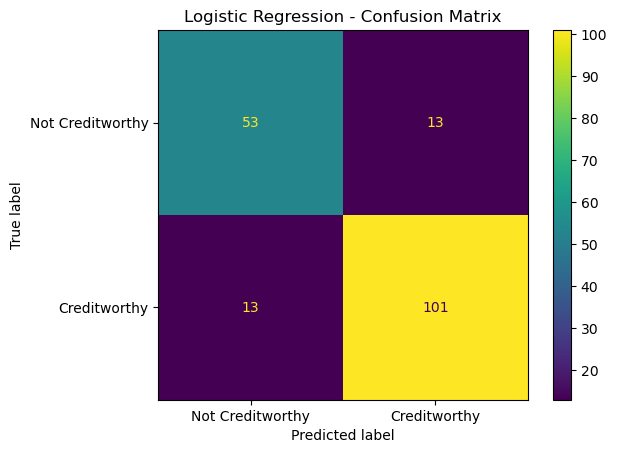

In [16]:
# Logistic Regression Confusion Matrix
cm = confusion_matrix(y_test,y_pred_lr,labels=["No", "Yes"])

D = ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=["Not Creditworthy", "Creditworthy"])

D.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [19]:
# Decision Tree
decision_tree = Pipeline(steps=[("preprocessor", preprocessor),
                                ("classifier",DecisionTreeClassifier(
                                    max_depth=6,random_state=42))])
decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]


In [20]:
# Evaluate Decission Tree
print("DECISION TREE")
print("Accuracy:",accuracy_score(y_test, y_pred_dt))
print("Precision:",precision_score(y_test, y_pred_dt, pos_label="Yes"))
print("Recall:",recall_score(y_test, y_pred_dt, pos_label="Yes"))
print("F1 Score:",f1_score(y_test, y_pred_dt, pos_label="Yes"))
print("ROC-AUC:",roc_auc_score(
          (y_test == "Yes").astype(int),
          y_prob_dt))

DECISION TREE
Accuracy: 0.8222222222222222
Precision: 0.8360655737704918
Recall: 0.8947368421052632
F1 Score: 0.864406779661017
ROC-AUC: 0.7819643806485912


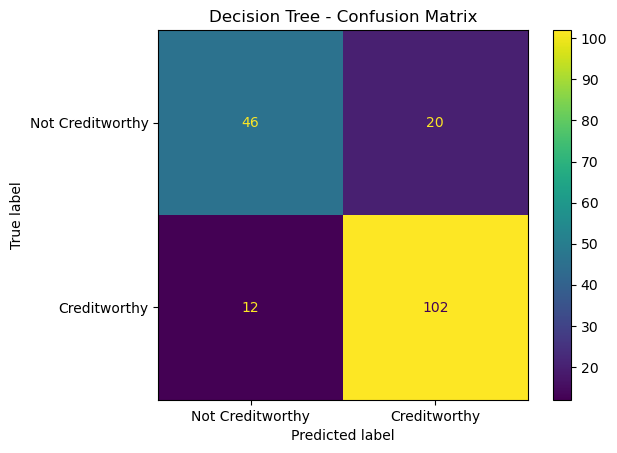

In [21]:
# Decision Tree Confusion Matrix

cm = confusion_matrix(y_test, y_pred_dt, labels= ["No", "Yes"])

D = ConfusionMatrixDisplay(confusion_matrix=cm,
                           display_labels=["Not Creditworthy", "Creditworthy"])

D.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [22]:
# Random Forest
random_forest = Pipeline(steps=[("preprocessor", preprocessor),
                                ("classifier",RandomForestClassifier(
                                    n_estimators=200,max_depth=10,random_state=42))])
random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

In [23]:
# Evaluate Random Forest  
print("RANDOM FOREST")
print("Accuracy:",accuracy_score(y_test, y_pred_rf))
print("Precision:",precision_score(y_test, y_pred_rf, pos_label="Yes"))
print("Recall:",recall_score(y_test, y_pred_rf, pos_label="Yes"))
print("F1 Score:",f1_score(y_test, y_pred_rf, pos_label="Yes")) 
print("ROC-AUC:",roc_auc_score(
          (y_test == "Yes").astype(int),
          y_prob_rf))

RANDOM FOREST
Accuracy: 0.85
Precision: 0.8717948717948718
Recall: 0.8947368421052632
F1 Score: 0.8831168831168831
ROC-AUC: 0.9239766081871345


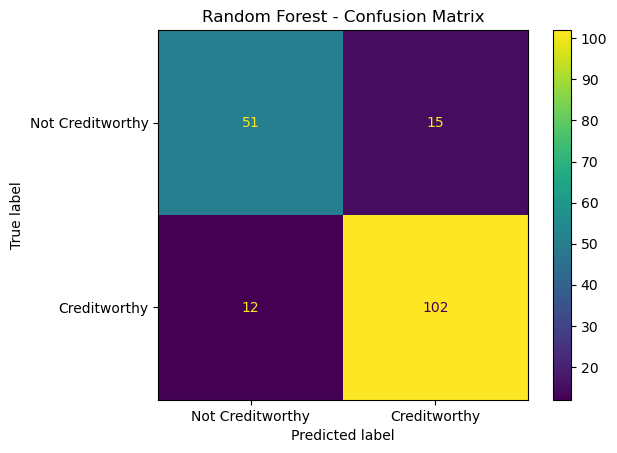

In [24]:
# Random Forest - Confusion Maatrix

cm = confusion_matrix(y_test,y_pred_rf,labels=["No", "Yes"])

D = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Not Creditworthy", "Creditworthy"])

D.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [25]:
# compare the models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, pos_label="Yes"),
        precision_score(y_test, y_pred_dt, pos_label="Yes"),
        precision_score(y_test, y_pred_rf, pos_label="Yes")
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, pos_label="Yes"),
        recall_score(y_test, y_pred_dt, pos_label="Yes"),
        recall_score(y_test, y_pred_rf, pos_label="Yes")
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_lr, pos_label="Yes"),
        f1_score(y_test, y_pred_dt, pos_label="Yes"),
        f1_score(y_test, y_pred_rf, pos_label="Yes")
    ],

    "ROC-AUC": [
        roc_auc_score(
            (y_test == "Yes").astype(int),y_prob_lr),
        roc_auc_score(
            (y_test == "Yes").astype(int),y_prob_dt),
        roc_auc_score(
            (y_test == "Yes").astype(int),y_prob_rf)
    ]
})
results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.856,0.886,0.886,0.886,0.942
1,Decision Tree,0.822,0.836,0.895,0.864,0.782
2,Random Forest,0.850,0.872,0.895,0.883,0.924


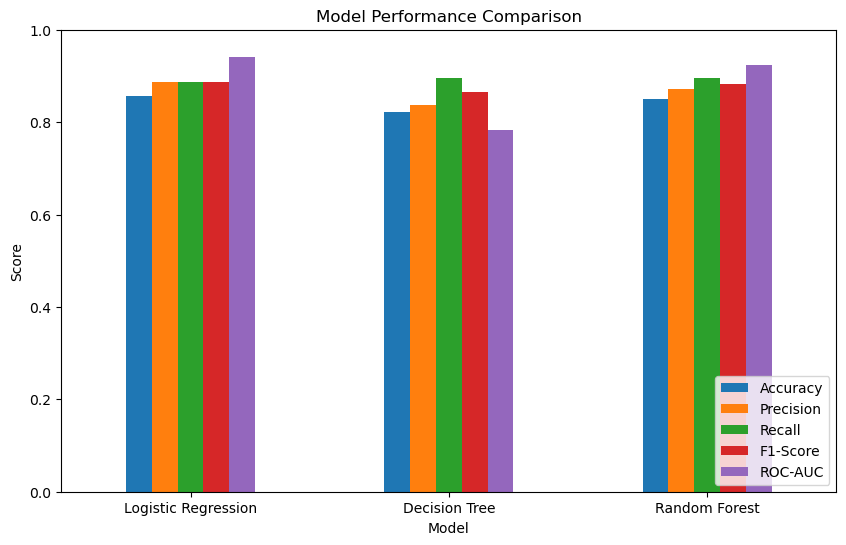

In [26]:
#Visualize the Model Comparison
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(kind="bar",figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()


In [27]:
# Predict new applicant

new_applicant = pd.DataFrame({
    "Age": [30],
    "Employment_Status": ["Employed"],
    "Employment_Years": [6.5],
    "Annual_Income": [750000],
    "Monthly_Income": [62500],
    "Monthly_Expenses": [28000],
    "Credit_History_Length_Years": [7],
    "Credit_Score": [735],
    "Number_of_Loans": [2],
    "Loan_Amount": [300000],
    "Total_Debt": [250000],
    "Debt_to_Income_Ratio": [0.333],
    "Missed_Payments": [0],
    "Late_Payments": [1],
    "Payment_History": ["Good"],
    "Credit_Utilization": [28.5],
    "Savings": [200000],
    "Previous_Default": ["No"],
    "Savings_to_Income_Ratio": [200000 / 750000],
    "Expense_to_Income_Ratio": [28000 / 62500],
    "Loan_to_Income_Ratio": [300000 / 750000]
})

# Random Forest prediction
prediction = random_forest.predict(new_applicant)
probability = random_forest.predict_proba(new_applicant)

print("Predicted Creditworthiness:", prediction[0])
print("Probability of Creditworthy:",probability[0][1])

Predicted Creditworthiness: Yes
Probability of Creditworthy: 0.9291986897199968
